# Пример 19. Изменение базиса образа ядра

## Тема

**Раздел книги:** Линейная алгебра.  
**Математическая тема:** ядро и образ эндоморфизма, матрица перехода и смена базиса $\tilde{A}=P^{-1}AP$ (подобие), инварианты подобия (след, определитель, собственные значения); связь с диагонализацией, PCA, whitening и анализом устойчивости динамики оптимизатора через спектр гессиана.

## Условие
Рассмотрим эндоморфизм $\Phi:\mathbb{R}^3\to\mathbb{R}^3$ с матрицей относительно стандартного базиса
$$
A_\Phi=\begin{bmatrix}1&1&0\\1&-1&0\\1&1&1\end{bmatrix}.
$$
**(a)** Определите $\ker(\Phi)$ и $\mathrm{Im}(\Phi)$.
**(b)** Найдите матрицу $\tilde{A}_\Phi$ того же преобразования относительно базиса
$$
B=\left(\begin{bmatrix}1\\1\\1\end{bmatrix},\ \begin{bmatrix}1\\2\\1\end{bmatrix},\ \begin{bmatrix}1\\0\\0\end{bmatrix}\right),
$$
т.е. выполните изменение базиса к новому базису $B$.

## Математическая идея
**Ядро** $\ker\Phi=\{x:A_\Phi x=0\}$ ищется как пространство решений однородной системы; его размерность — дефект. **Образ** $\mathrm{Im}\Phi=\mathrm{col}(A_\Phi)$ — столбцовое пространство (ср. 14), размерность равна рангу. Связывает их теорема о ранге и дефекте: $\dim\ker\Phi+\operatorname{rank}A_\Phi=3$.

**Смена базиса.** Если столбцы $P$ — векторы нового базиса $B$, то координаты одного и того же вектора в двух базисах связаны как $x_{\text{old}}=P\,x_{\text{new}}$. Подставляя в $y_{\text{old}}=A\,x_{\text{old}}$ и выражая $y_{\text{new}}$, получаем матрицу оператора в новом базисе:
$$
\tilde{A}=P^{-1}AP.
$$
Это **подобие**, поэтому $\tilde{A}$ сохраняет след, определитель и собственные значения — они служат контролем правильности вычислений.

## Решение

**(a) Ядро и образ.** Решаем $A_\Phi x=0$:
$$
\begin{cases}x_1+x_2=0\\ x_1-x_2=0\\ x_1+x_2+x_3=0\end{cases}
\Rightarrow x_1=x_2=0,\ x_3=0.
$$
Значит $\ker(\Phi)=\{\mathbf{0}\}$, $\dim\ker=0$. Определитель $A_\Phi=1(-1)-1(1)=-2\neq0$ ⇒ $\operatorname{rank}=3$, поэтому
$$
\mathrm{Im}(\Phi)=\mathbb{R}^3,\quad \dim\mathrm{Im}=3.
$$
Контроль: $0+3=3$ ✓. Базис образа — любые три независимых столбца $A_\Phi$ (например, все три).

**(b) Матрица перехода и $\tilde{A}_\Phi$.**
$$
P=\begin{bmatrix}1&1&1\\1&2&0\\1&1&0\end{bmatrix},\quad \det P=-1,\quad
P^{-1}=\begin{bmatrix}0&-1&2\\0&1&-1\\1&0&-1\end{bmatrix}.
$$
Считаем по шагам:
$$
AP=\begin{bmatrix}2&3&1\\0&-1&1\\3&4&1\end{bmatrix},\qquad
\tilde{A}=P^{-1}AP=\begin{bmatrix}6&9&1\\-3&-5&0\\-1&-1&0\end{bmatrix}.
$$
**Контроль инвариантов подобия:** $\operatorname{tr}A_\Phi=1-1+1=1=\operatorname{tr}\tilde{A}=6-5+0$ ✓; $\det A_\Phi=-2=\det\tilde{A}$ ✓.

**Ответ:** $\ker\Phi=\{0\}$, $\mathrm{Im}\Phi=\mathbb{R}^3$; $\tilde{A}_\Phi=\begin{bmatrix}6&9&1\\-3&-5&0\\-1&-1&0\end{bmatrix}$.

In [2]:
import numpy as np

A = np.array([[1, 1, 0], [1, -1, 0], [1, 1, 1]], dtype=float)

# (a) ядро через SVD (строки Vh с индекса rank)
_, s, Vh = np.linalg.svd(A)
r = np.linalg.matrix_rank(A)
ker = Vh[r:].T
print(f"(a) rank={r}, dim rank{ker.shape[1]} -> ker={{0}}; dim Im={r} -> Im R^3")

# (b) смена базиса
P = np.array([[1, 1, 1,], [1, 2, 0], [1, 1, 0]], dtype=float)
A_tilde = np.linalg.inv(P) @ A @ P
print(f"(b) A_tilde =\n {np.round(A_tilde, 6)}")

# Контроль инвариантов подобия
print(f"tr(A)={np.trace(A)}, tr(A_tilde)={np.trace(A_tilde)}")
print(f"det(A)={np.linalg.det(A)}, det(A_tilde)={np.linalg.det(A_tilde)}")
print("eig(A)==eig(A_tilde)?", np.allclose(np.sort(np.linalg.eigvals(A).real),
                                                   np.sort(np.linalg.eigvals(A_tilde).real)))

(a) rank=3, dim rank0 -> ker={0}; dim Im=3 -> Im R^3
(b) A_tilde =
 [[ 6.  9.  1.]
 [-3. -5.  0.]
 [-1. -1.  0.]]
tr(A)=1.0, tr(A_tilde)=1.0
det(A)=-2.0, det(A_tilde)=-1.9999999999999998
eig(A)==eig(A_tilde)? True


## Дополнительный пример: смена базиса как диагонализация (PCA / whitening)

**Идея.** Выбор $P$ из собственных векторов $A$ превращает $\tilde{A}=P^{-1}AP$ в **диагональную** матрицу с собственными значениями на диагонали — это спектральное разложение. В ML именно так работают: **PCA** (диагонализация ковариационной матрицы $C=Q\Lambda Q^\top$), **whitening** (переход в базис, где признаки некоррелированы и имеют единичную дисперсию), и анализ **устойчивости оптимизатора** (спектр гессиана задаёт допустимый шаг обучения). Смена базиса из 19(b) — частный случай: оператор тот же, но в «удобных» координатах он проще.

In [3]:
import numpy as np

# Диагонализация симметричной ковариационной матрицы (аналог PCA)
C = np.array([[4,2,0],[2,3,1],[0,1,2]], dtype=float)
lam, Q = np.linalg.eigh(C)            # Q — ортонормированный базис собств. векторов
C_diag = Q.T @ C @ Q                  # подобие с P=Q -> диагональная матрица
print("Собств. значения:", np.round(np.sort(lam), 4))
print("C в собственном базисе (почти диагональна):\n", np.round(C_diag, 6))
print("След инвариантен:", np.trace(C), "==", np.trace(C_diag))

Собств. значения: [0.8549 2.476  5.6691]
C в собственном базисе (почти диагональна):
 [[ 0.854897 -0.       -0.      ]
 [-0.        2.476024  0.      ]
 [-0.       -0.        5.669079]]
След инвариантен: 9.0 == 8.999999999999996


## Визуализация: один оператор в двух базисах

Показываем, что $\tilde{A}$ (правая панель) — это то же действие, что и $A$ (левая), но записанное в координатах базиса $B$: сетка плоскости $(x_1,x_2)$ деформируется оператором, а наклон ячеек отражает переход к новому базису. Подписи осей и инварианты (след/определитель) совпадают на обеих панелях.

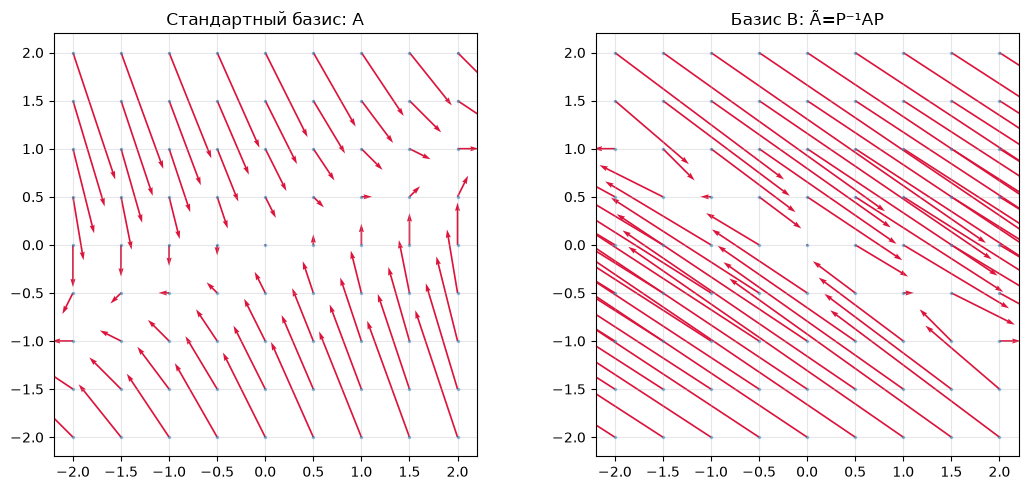

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Сетка в 2D-срезе (x3=0) для наглядности; применяем 2x2 блоки A и A_tilde
A2  = A[:2,:2]
At2 = np.array([[6,9],[-3,-5]])
g = np.linspace(-2,2,9)
X,Y = np.meshgrid(g,g)
pts = np.vstack([X.ravel(), Y.ravel()])

fig, ax = plt.subplots(1,2, figsize=(11,5))
for a,(M,title) in zip(ax,[(A2,'Стандартный базис: A'),(At2,'Базис B: Ã=P⁻¹AP')]):
    out = M @ pts
    ax_idx = list(a.get_subplotspec().get_geometry())
    a.plot(pts[0], pts[1], '.', ms=3, alpha=.4)
    a.quiver(pts[0], pts[1], out[0]-pts[0], out[1]-pts[1],
             scale=20, width=.004, color='crimson')
    a.set_title(title); a.set_aspect('equal'); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## Проверка результата

В первой части ядро найдено как пространство решений однородной системы и подтверждено ненулевым определителем ($\det A_\Phi=-2$), откуда $\dim\ker=0$ и $\dim\mathrm{Im}=3$; это согласуется с теоремой о ранге и дефекте $0+3=3$. Во второй части матрица $\tilde{A}=P^{-1}AP$ вычислена вручную и сверена тремя независимыми инвариантами подобия: след ($\operatorname{tr}A=\operatorname{tr}\tilde{A}=1$), определитель ($\det A=\det\tilde{A}=-2$) и совпадение спектров собственных значений; дополнительно матрица перехода проверена равенством $PP^{-1}=I$, а обратимость $P$ подтверждена $\det P=-1\neq0$, что исключает вырожденный выбор базиса.

## Вывод

Эндоморфизм с невырожденной матрицей имеет тривиальное ядро и полный образ, а смена базиса через $\tilde{A}=P^{-1}AP$ (подобие) не меняет ни оператора как геометрического объекта, ни его инвариантов — следа, определителя и собственных значений, но меняет матричную запись, делая её проще в «правильных» координатах. Продемонстрированы ключевые идеи главы — ядро, образ, ранг и дефект, матрица перехода и подобие. В машинном обучении тот же механизм лежит в основе PCA и whitening (диагонализация ковариации), спектрального анализа устойчивости градиентного спуска и вообще любых методов, где удобно перейти в базис собственных векторов, оставаясь тем же линейным преобразованием.